In [1]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
TRAIN_PATH = "../data/splits/train.parquet"
TEST_PATH = "../data/splits/test.parquet"

train_df = pd.read_parquet(TRAIN_PATH)
test_df = pd.read_parquet(TEST_PATH)

print(f"Training rows: {len(train_df):,}")
print(f"Testing rows:  {len(test_df):,}")
print(f"Features:      {len(train_df.columns) - 1}")

Training rows: 1,785,012
Testing rows:  446,254
Features:      69


In [3]:
TARGET = "BinaryLabel"

X_train = train_df.drop(columns=[TARGET])
y_train = train_df[TARGET]

X_test = test_df.drop(columns=[TARGET])
y_test = test_df[TARGET]

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

X_train: (1785012, 69)
X_test:  (446254, 69)
y_train: (1785012,)
y_test:  (446254,)


In [4]:
print("Training labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

Training labels:
BinaryLabel
0    1516035
1     268977
Name: count, dtype: int64

Testing labels:
BinaryLabel
0    379009
1     67245
Name: count, dtype: int64


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [6]:
model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    solver="lbfgs",
    random_state=42
)

start_time = time.time()

model.fit(
    X_train_scaled,
    y_train
)

training_time = time.time() - start_time

print(f"Training completed in {training_time:.2f} seconds.")

Training completed in 95.89 seconds.


In [7]:
y_pred = model.predict(X_test_scaled)

y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [8]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

pr_auc = average_precision_score(
    y_test,
    y_prob
)

print("=" * 60)
print("LOGISTIC REGRESSION RESULTS")
print("=" * 60)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")
print(f"PR-AUC   : {pr_auc:.4f}")

print("=" * 60)

LOGISTIC REGRESSION RESULTS
Accuracy : 0.9460
Precision: 0.7462
Recall   : 0.9722
F1-score : 0.8443
ROC-AUC  : 0.9932
PR-AUC   : 0.9730


In [9]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["BENIGN", "ATTACK"],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      BENIGN     0.9948    0.9413    0.9673    379009
      ATTACK     0.7462    0.9722    0.8443     67245

    accuracy                         0.9460    446254
   macro avg     0.8705    0.9568    0.9058    446254
weighted avg     0.9573    0.9460    0.9488    446254



In [10]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[356768  22241]
 [  1867  65378]]


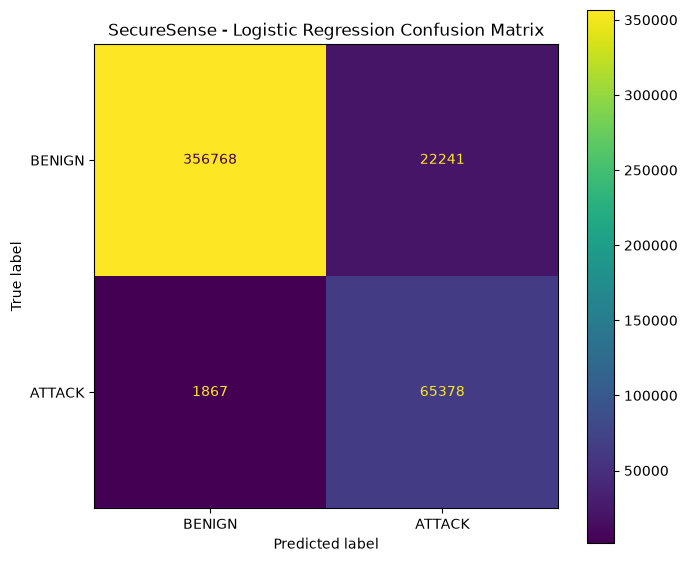

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["BENIGN", "ATTACK"]
).plot(
    ax=ax,
    values_format="d"
)

ax.set_title("SecureSense - Logistic Regression Confusion Matrix")

plt.tight_layout()
plt.show()

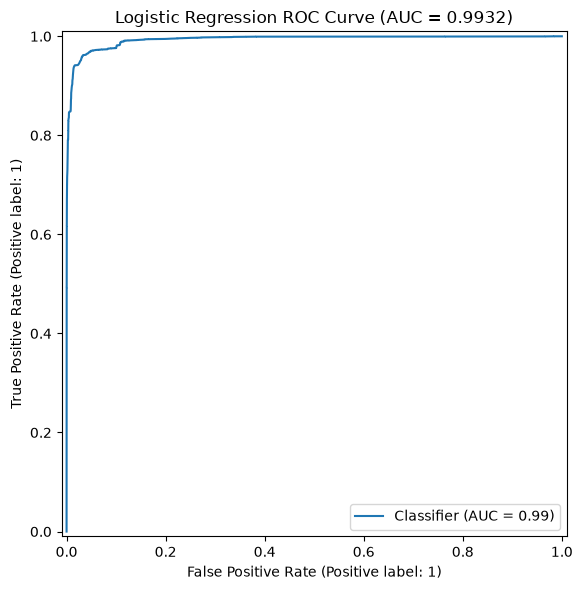

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    ax=ax
)

ax.set_title(
    f"Logistic Regression ROC Curve (AUC = {roc_auc:.4f})"
)

plt.tight_layout()
plt.show()

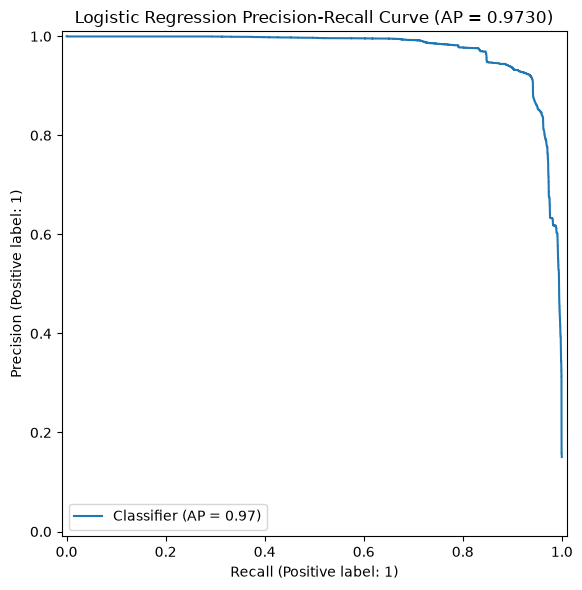

In [13]:
fig, ax = plt.subplots(figsize=(7, 6))

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob,
    ax=ax
)

ax.set_title(
    f"Logistic Regression Precision-Recall Curve (AP = {pr_auc:.4f})"
)

plt.tight_layout()
plt.show()

In [14]:
import joblib

MODEL_DIR = "../models"

os.makedirs(MODEL_DIR, exist_ok=True)

joblib.dump(
    model,
    os.path.join(
        MODEL_DIR,
        "logistic_regression.pkl"
    )
)

joblib.dump(
    scaler,
    os.path.join(
        MODEL_DIR,
        "logistic_regression_scaler.pkl"
    )
)

print("Model and scaler saved successfully.")

Model and scaler saved successfully.


In [15]:
metrics = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "ROC_AUC": roc_auc,
    "PR_AUC": pr_auc,
    "Training_Time_Seconds": training_time
}

metrics_df = pd.DataFrame([metrics])

metrics_path = "../models/logistic_regression_metrics.csv"

metrics_df.to_csv(
    metrics_path,
    index=False
)

metrics_df

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Training_Time_Seconds
0,Logistic Regression,0.945977,0.746162,0.972236,0.844328,0.993169,0.97305,95.89343


In [ ]:
# ============================================================
# SECURESENSE - FINAL GROUP-AWARE LOGISTIC REGRESSION
# ============================================================

import os
import time
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# ============================================================
# PATHS
# ============================================================
PROJECT_ROOT = r"W:\FinalYearProject\SecureSense_Project"

TRAIN_PATH = r"W:\FinalYearProject\SecureSense_Project\notebooks\data\final_group_splits\train.parquet"

TEST_PATH = r"W:\FinalYearProject\SecureSense_Project\notebooks\data\final_group_splits\test.parquet"



MODEL_DIR = os.path.join(PROJECT_ROOT, "models")
RESULT_DIR = os.path.join(PROJECT_ROOT, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

# ============================================================
# LOAD
# ============================================================

print("=" * 80)
print("SECURESENSE - FINAL GROUP-AWARE LOGISTIC REGRESSION")
print("=" * 80)

train_df = pd.read_parquet(TRAIN_PATH)
test_df = pd.read_parquet(TEST_PATH)

TARGET = "BinaryLabel"

X_train = train_df.drop(
    columns=["BinaryLabel", "Label", "_source_file"],
    errors="ignore"
)

X_test = test_df.drop(
    columns=["BinaryLabel", "Label", "_source_file"],
    errors="ignore"
)

y_train = train_df[TARGET].map({
    "BENIGN": 0,
    "ATTACK": 1
})

y_test = test_df[TARGET].map({
    "BENIGN": 0,
    "ATTACK": 1
})

print(f"\nTraining shape: {X_train.shape}")
print(f"Testing shape : {X_test.shape}")

# ============================================================
# SCALE - FIT ONLY ON TRAIN
# ============================================================

print("\nScaling features...")

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ============================================================
# TRAIN
# ============================================================

print("\nTraining Logistic Regression...")

model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    solver="lbfgs",
    random_state=42
)

start = time.time()

model.fit(X_train_scaled, y_train)

training_time = time.time() - start

print(f"Training time: {training_time:.2f} seconds")

# ============================================================
# PREDICTION
# ============================================================

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# ============================================================
# METRICS
# ============================================================

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)

print("\n" + "=" * 80)
print("FINAL LOGISTIC REGRESSION RESULTS")
print("=" * 80)

print(f"Accuracy  : {accuracy:.6f} ({accuracy*100:.2f}%)")
print(f"Precision : {precision:.6f} ({precision*100:.2f}%)")
print(f"Recall    : {recall:.6f} ({recall*100:.2f}%)")
print(f"F1 Score  : {f1:.6f} ({f1*100:.2f}%)")
print(f"ROC-AUC   : {roc_auc:.6f} ({roc_auc*100:.2f}%)")
print(f"PR-AUC    : {pr_auc:.6f} ({pr_auc*100:.2f}%)")
print(f"Training Time: {training_time:.2f} seconds")

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 80)
print("CLASSIFICATION REPORT")
print("=" * 80)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["BENIGN", "ATTACK"],
        digits=4,
        zero_division=0
    )
)

# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["BENIGN", "ATTACK"]
).plot()

plt.title("Final Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

# ============================================================
# ROC CURVE
# ============================================================

RocCurveDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title("Final Logistic Regression - ROC Curve")
plt.tight_layout()
plt.show()

# ============================================================
# PR CURVE
# ============================================================

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title("Final Logistic Regression - Precision-Recall Curve")
plt.tight_layout()
plt.show()

# ============================================================
# SAVE MODEL + SCALER
# ============================================================

model_path = os.path.join(
    MODEL_DIR,
    "final_logistic_regression.pkl"
)

scaler_path = os.path.join(
    MODEL_DIR,
    "final_logistic_regression_scaler.pkl"
)

joblib.dump(model, model_path)
joblib.dump(scaler, scaler_path)

# ============================================================
# SAVE METRICS
# ============================================================

metrics = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Evaluation": "Final Group-Aware",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "ROC_AUC": roc_auc,
    "PR_AUC": pr_auc,
    "Training_Time_Seconds": training_time
}])

metrics_path = os.path.join(
    RESULT_DIR,
    "final_logistic_regression_metrics.csv"
)

metrics.to_csv(metrics_path, index=False)

# ============================================================
# FINAL
# ============================================================

print("\n" + "=" * 80)
print("FINAL LOGISTIC REGRESSION COMPLETED")
print("=" * 80)

print(f"\nModel saved  : {model_path}")
print(f"Scaler saved : {scaler_path}")
print(f"Metrics saved: {metrics_path}")

print("\n✓ Evaluation performed on completely unseen source files.")